In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer

RANDOM_STATE = 42

df = pd.read_csv("insurance.csv")

df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


Primeres files:


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520



Files inicials: 1338
Columnes: 7

Duplicats trobats: 1
Files després d'eliminar duplicats: 1337

Valors nuls:
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

Variables numèriques: ['age', 'bmi', 'children']
Variables categòriques: ['sex', 'smoker', 'region']
Target: charges

Mitjana general de charges: 13279.12

Resultats segons sex


,sex,Persones,Charges mitjà,Diferència (%)
0,female,662,12569.58,-5.34
1,male,675,13975.00,5.24



Resultats segons smoker


,smoker,Persones,Charges mitjà,Diferència (%)
0,no,1063,8440.66,-36.44
1,yes,274,32050.23,141.36



Resultats segons region


,region,Persones,Charges mitjà,Diferència (%)
0,northeast,324,13406.38,0.96
1,northwest,324,12450.84,-6.24
2,southeast,364,14735.41,10.97
3,southwest,325,12346.94,-7.02


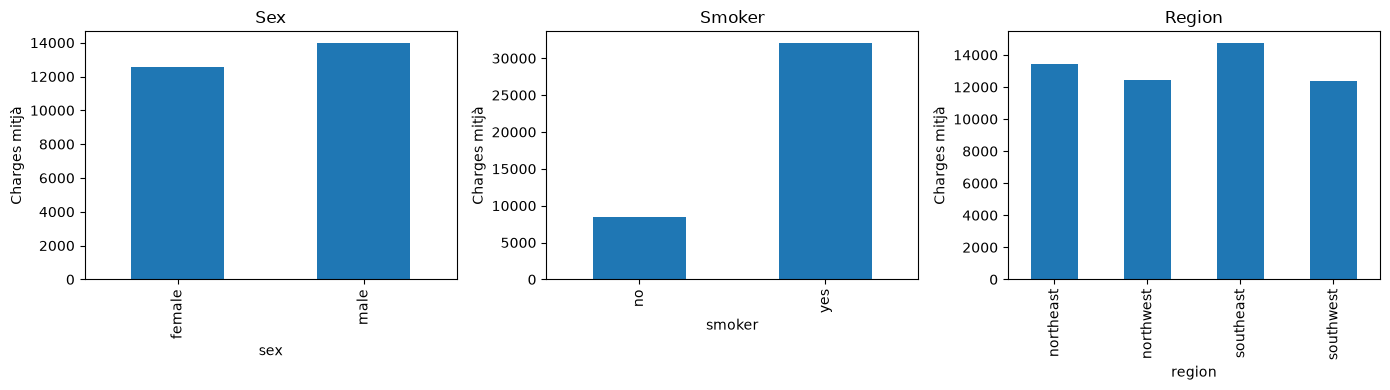


Correlació de variables numèriques:


,Variable,Correlació amb charges
0,age,0.298
1,bmi,0.198
2,children,0.067



Relació individual amb charges:


,Atribut,% variació explicada
4,smoker,61.97
0,age,8.90
2,bmi,3.94
5,region,0.65
3,children,0.45
1,sex,0.34



Relació entre parelles d'atributs:


,Atribut 1,% Atribut 1,Atribut 2,% Atribut 2,% Junts,Millora
3,age,8.90,smoker,61.97,72.12,10.15
10,bmi,3.94,smoker,61.97,65.79,3.82
12,children,0.45,smoker,61.97,62.35,0.38
14,smoker,61.97,region,0.65,62.03,0.05
7,sex,0.34,smoker,61.97,61.97,0.00
1,age,8.90,bmi,3.94,11.68,2.78
4,age,8.90,region,0.65,9.61,0.72
0,age,8.90,sex,0.34,9.31,0.41
2,age,8.90,children,0.45,9.20,0.30
9,bmi,3.94,children,0.45,4.36,0.42



Variació de charges explicada utilitzant tots els atributs: 75.07 %

Train: (802, 6)
Validation: (267, 6)
Test: (268, 6)

Dades després del preprocessament:
Train: (802, 11)
Validation: (267, 11)
Test: (268, 11)

Columnes finals:
['numeriques__age' 'numeriques__bmi' 'numeriques__children'
 'categoriques__sex_female' 'categoriques__sex_male'
 'categoriques__smoker_no' 'categoriques__smoker_yes'
 'categoriques__region_northeast' 'categoriques__region_northwest'
 'categoriques__region_southeast' 'categoriques__region_southwest']


In [ ]:
# =========================================================
# CAS KAGGLE - INSURANCE
# ANÀLISI I PREPROCESSAMENT FINAL
# =========================================================

import pandas as pd
import matplotlib.pyplot as plt

from itertools import combinations
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer


# ---------------------------------------------------------
# 1. Carregar i netejar dataset
# ---------------------------------------------------------

df = pd.read_csv("insurance.csv")

print("Primeres files:")
display(df.head())

print("\nFiles inicials:", len(df))
print("Columnes:", len(df.columns))

print("\nDuplicats trobats:", df.duplicated().sum())

df = df.drop_duplicates().reset_index(drop=True)

print("Files després d'eliminar duplicats:", len(df))

print("\nValors nuls:")
print(df.isnull().sum())


# ---------------------------------------------------------
# 2. Definir variables
# ---------------------------------------------------------

variables_numericas = ["age","bmi","children"]
variables_categoricas = ["sex","smoker","region"]
atributs = ["age","sex","bmi","children","smoker","region"]
target = "charges"

print("\nVariables numèriques:", variables_numericas)
print("Variables categòriques:", variables_categoricas)
print("Target:", target)


# =========================================================
# ANÀLISI DE LES DADES
# =========================================================


# ---------------------------------------------------------
# 3. Analitzar variables categòriques
# ---------------------------------------------------------

media_general = df[target].mean()

print("\nMitjana general de charges:", round(media_general,2))


for variable in variables_categoricas:

    taula = df.groupby(variable)[target].agg(["count","mean"]).reset_index()

    taula["Diferència (%)"] = ((taula["mean"] - media_general) / media_general) * 100

    taula.columns = [variable,"Persones","Charges mitjà","Diferència (%)"]

    taula["Charges mitjà"] = taula["Charges mitjà"].round(2)
    taula["Diferència (%)"] = taula["Diferència (%)"].round(2)

    print("\nResultats segons", variable)
    display(taula)


# ---------------------------------------------------------
# 4. Gràfics de variables categòriques
# ---------------------------------------------------------

fig, axes = plt.subplots(1,3,figsize=(14,4))

df.groupby("sex")[target].mean().plot(kind="bar",ax=axes[0],title="Sex")
df.groupby("smoker")[target].mean().plot(kind="bar",ax=axes[1],title="Smoker")
df.groupby("region")[target].mean().plot(kind="bar",ax=axes[2],title="Region")

axes[0].set_ylabel("Charges mitjà")
axes[1].set_ylabel("Charges mitjà")
axes[2].set_ylabel("Charges mitjà")

plt.tight_layout()
plt.show()


# ---------------------------------------------------------
# 5. Correlació de variables numèriques
# ---------------------------------------------------------

resultats_correlacio = []

for variable in variables_numericas:

    correlacio = df[variable].corr(df[target])

    resultats_correlacio.append([variable,correlacio])


taula_correlacio = pd.DataFrame(
    resultats_correlacio,
    columns=["Variable","Correlació amb charges"]
)

taula_correlacio["Correlació amb charges"] = taula_correlacio["Correlació amb charges"].round(3)

print("\nCorrelació de variables numèriques:")
display(taula_correlacio)


# ---------------------------------------------------------
# 6. Percentatge de variació explicada
# ---------------------------------------------------------

# Aquesta funció permet utilitzar tant variables numèriques
# com categòriques.
#
# Les categòriques es transformen a 0/1 i després fem
# una regressió lineal.
#
# El R² ens indica el percentatge de variació de charges
# que poden explicar les variables utilitzades.

def percentatge_explicat(variables):

    X_analisi = df[variables].copy()

    X_analisi = pd.get_dummies(X_analisi,drop_first=True,dtype=int)

    y_analisi = df[target]

    model = LinearRegression()
    model.fit(X_analisi,y_analisi)

    r2 = model.score(X_analisi,y_analisi)

    return r2 * 100


# ---------------------------------------------------------
# 7. Relació individual de cada atribut
# ---------------------------------------------------------

resultats_individuals = []

for atribut in atributs:

    percentatge = percentatge_explicat([atribut])

    resultats_individuals.append([atribut,percentatge])


taula_individual = pd.DataFrame(
    resultats_individuals,
    columns=["Atribut","% variació explicada"]
)

taula_individual["% variació explicada"] = taula_individual["% variació explicada"].round(2)

taula_individual = taula_individual.sort_values("% variació explicada",ascending=False)

print("\nRelació individual amb charges:")
display(taula_individual)


# ---------------------------------------------------------
# 8. Relació entre parelles d'atributs
# ---------------------------------------------------------

resultats_parelles = []

for atribut1, atribut2 in combinations(atributs,2):

    percentatge1 = percentatge_explicat([atribut1])
    percentatge2 = percentatge_explicat([atribut2])

    percentatge_junts = percentatge_explicat([atribut1,atribut2])

    millor_individual = max(percentatge1,percentatge2)

    millora = percentatge_junts - millor_individual

    resultats_parelles.append([
        atribut1,
        percentatge1,
        atribut2,
        percentatge2,
        percentatge_junts,
        millora
    ])


taula_parelles = pd.DataFrame(
    resultats_parelles,
    columns=[
        "Atribut 1",
        "% Atribut 1",
        "Atribut 2",
        "% Atribut 2",
        "% Junts",
        "Millora"
    ]
)

columnes_percentatge = ["% Atribut 1","% Atribut 2","% Junts","Millora"]

taula_parelles[columnes_percentatge] = taula_parelles[columnes_percentatge].round(2)

taula_parelles = taula_parelles.sort_values("% Junts",ascending=False)

print("\nRelació entre parelles d'atributs:")
display(taula_parelles)


# ---------------------------------------------------------
# 9. Relació utilitzant tots els atributs
# ---------------------------------------------------------

percentatge_total = percentatge_explicat(atributs)

print(
    "\nVariació de charges explicada utilitzant tots els atributs:",
    round(percentatge_total,2),
    "%"
)


# =========================================================
# PREPROCESSAMENT FINAL
# =========================================================


# ---------------------------------------------------------
# 10. Separar atributs i target
# ---------------------------------------------------------

X = df.drop(columns=[target])
y = df[target]


# ---------------------------------------------------------
# 11. Separar Train / Validation / Test
# ---------------------------------------------------------

# 60% train - 20% validation - 20% test

X_train, X_resto, y_train, y_resto = train_test_split(
    X,y,test_size=0.40,random_state=42
)

X_val, X_test, y_val, y_test = train_test_split(
    X_resto,y_resto,test_size=0.50,random_state=42
)

print("\nTrain:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)


# ---------------------------------------------------------
# 12. Crear preprocessador
# ---------------------------------------------------------

preprocessador = ColumnTransformer([
    ("numeriques",StandardScaler(),variables_numericas),
    ("categoriques",OneHotEncoder(handle_unknown="ignore"),variables_categoricas)
])


# ---------------------------------------------------------
# 13. Aprendre només amb train
# ---------------------------------------------------------

preprocessador.fit(X_train)


# ---------------------------------------------------------
# 14. Transformar Train / Validation / Test
# ---------------------------------------------------------

X_train_preparat = preprocessador.transform(X_train)
X_val_preparat = preprocessador.transform(X_val)
X_test_preparat = preprocessador.transform(X_test)


# ---------------------------------------------------------
# 15. Resultat final
# ---------------------------------------------------------

print("\nDades després del preprocessament:")

print("Train:", X_train_preparat.shape)
print("Validation:", X_val_preparat.shape)
print("Test:", X_test_preparat.shape)

print("\nColumnes finals:")

columnes_finals = preprocessador.get_feature_names_out()

print(columnes_finals)